## Overview

This week you will be forecasting the incidence of COVID-19 cases. However, before forecasting you will begin by investigating the relationship between diabetes prevalence and COVID-19 incidence. 

This is split up into three notebooks

  1. Inspect correlations between diabetes and COVID-19 prevelance

  2. Implement LSTM model for COVID-19 forecasting and evaluate on state-level and county-level data.

  3. Visualize the performance of LSTM models trained on nation-level (pretrained), state-level, and county-level data. In addition, we will also visualize the performance of the ARIMA model (pretrained) using county-level data.

## <font color='magenta'>Your task</font>

In this notebook you will visualize the perfomance of various models. The results from Milwaukee county in Wisconsin state has been saved from the previous notebook ('results_wi_milwaukee.pkl'). In addition, we pretrained and saved the results for all counties using the nation-level data ('results_nation_all_counties.pkl') and also trained an ARIMA model for the county-level data ('assignment4/results_arima_Milwaukee.pkl').


You will need to recreate the plot shown below. This plot looks at how different models trained on different datasets perform at predicting COVID-19 cases for Milwaukee county.  


TIP: FIPS/GEOID for Milwaukee county is 55079
Make sure that the line types and colors match those from below.

Note:
- the hex color for the predicted new cases from Nation - LSTM is: #000000
- the hex color for the predicted new cases from Wisconsin - LSTM is: #7570b3
- the hex color for the predicted new cases from Milwaukee - LSTM is: #1b9e77
- the hex color for the predicted new cases from Milwaukee - ARIMA is: #e7298a
- the hex color for the actual new cases is: #66a61e

In [1]:
import warnings
warnings.simplefilter("ignore")

import pandas as pd
import numpy as np

import sys
import os
from mads.lib.path import assets

data_cleaners = assets.find("shared_files/assignment4/data_cleaners.py")
sys.path.append(os.path.dirname(data_cleaners))
import data_cleaners as dc

import matplotlib.pyplot as plt
import pickle

STATE = 'Wisconsin'
COUNTY = 'Milwaukee'
BURNIN_WEEKS = 14
NUM_BIWEEKLY_INTERVALS = 20 # after the burnin period

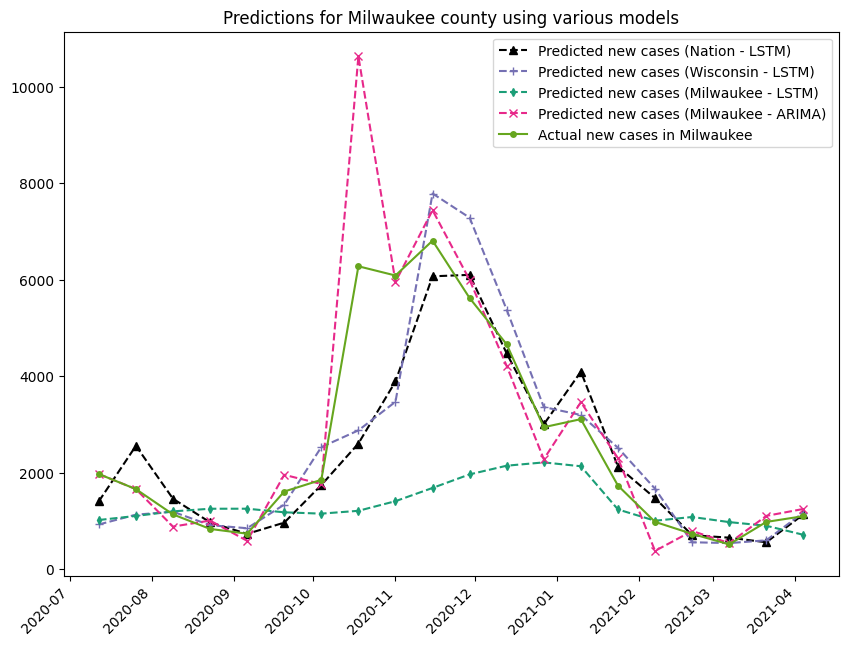

In [2]:
# Plot predicted new cases (50th quantile) vs actual new cases for the county at each interval using state model,
# county model, nation model.

import matplotlib.dates as mdates

# load the saved forecasts from the course assets
class CourseResultsUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        # map the old integer index class to the current pandas index
        if (module, name) == ("pandas.core.indexes.numeric", "Int64Index"):
            return pd.Index
        return super().find_class(module, name)

# load the national forecasts with the index compatibility fix
with open(assets.find("assignment4/results_nation_all_counties.pkl"), "rb") as file:
    nation = CourseResultsUnpickler(file).load()

with open(assets.find("assignment4/results_wi_milwaukee.pkl"), "rb") as file:
    wisconsin = pickle.load(file)

with open(assets.find("assignment4/results_arima_Milwaukee.pkl"), "rb") as file:
    arima = pickle.load(file)

# select Milwaukee's median case forecast from each national result
milwaukee_geoid = 55079
nation_cases = [
    frame.loc[frame["GEOID"].eq(milwaukee_geoid), "q_500_pred_cases"].item()
    for frame in nation["results"]
]

nation_dates = pd.to_datetime(nation["forecast_dates"])
wisconsin_dates = pd.to_datetime(wisconsin["forecast_dates"])
arima_dates = pd.to_datetime(arima["forecast_dates"])

fig, ax = plt.subplots(figsize = (10, 8))

# draw all four forecast lines with dashes
ax.plot(
    nation_dates, nation_cases, "--", color = "#000000", marker = "^",
    label = "Predicted new cases (Nation - LSTM)",
)
ax.plot(
    wisconsin_dates, wisconsin["pred_state_county_lstm"], "--", color = "#7570b3", marker = "+",
    label = "Predicted new cases (Wisconsin - LSTM)",
)
ax.plot(
    wisconsin_dates, wisconsin["pred_county_lstm"], "--", color="#1b9e77", marker="d", markersize = 4,
    label = "Predicted new cases (Milwaukee - LSTM)",
)
ax.plot(
    arima_dates, arima["pred_cases"], "--", color = "#e7298a", marker = "x",
    label = "Predicted new cases (Milwaukee - ARIMA)",
)

# draw the observed Milwaukee case counts as a solid line
ax.plot(
    wisconsin_dates, wisconsin["delta_cases_county"], "-", color = "#66a61e", marker = "o", markersize = 3.95,
    label = "Actual new cases in Milwaukee",
)

# label the date axis by month while keeping the biweekly data points
ax.set_title("Predictions for Milwaukee county using various models")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc = "upper right")
fig.autofmt_xdate(rotation = 45)
plt.show()

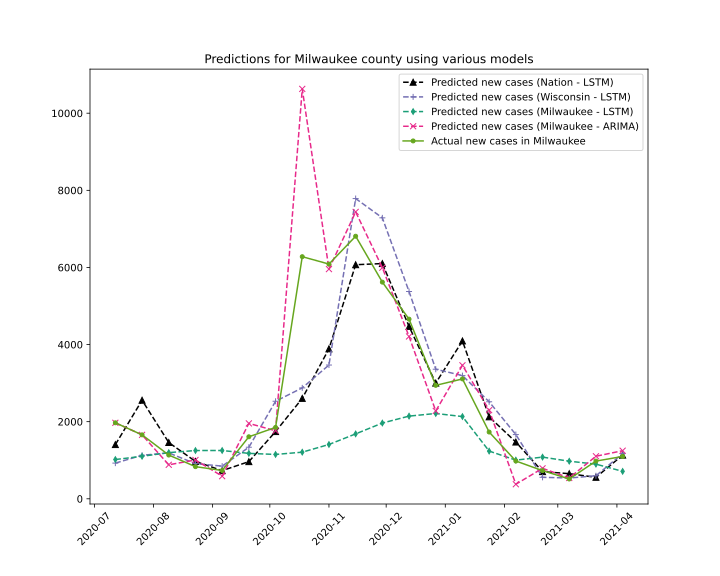

In [3]:
from IPython.display import SVG, display
def show_svg():
    display(SVG(filename=assets.find("assignment4/milwaukie_wi_predicted_cases.svg")))
show_svg()

## IMPORTANT: Uncomment the following code when you are ready to move on to the next assignment

In [4]:
script = assets.find('copy_shared_files.sh')
!bash {script}

=== Copying shared files back to coursework ===
✅ Shared files successfully copied back to coursework.


### Personal Notes:

---

| Series | Add to `ax.plot()` | Symbol |
|---|---|---|
| Nation – LSTM | `marker="^"` | Triangle |
| Wisconsin – LSTM | `marker="+"` | Plus |
| Milwaukee – LSTM | `marker="d"` | Thin diamond |
| Milwaukee – ARIMA | `marker="x"` | X |
| Actual new cases | `marker="o"` | Circle |

- Add `markersize=` to each `ax.plot()` call you want to adjust. It changes the symbol size in points, both on the plot and in the legend.